## Reducing neutrino production uncertainty with a multi-axis fit

In [39]:
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython import display

from analysis_helper import (
    initialize_flux_dir,
    initialize_fluxes,
    initialize_scaling,
    initialize_xsecs,
    makeeventsmeas_fitparams_eff,
    muon_0,
    muon_1,
)


1. Make inflated neutrino datasets - 
run `python offaxis_fluxes_loop.py 0.0 0 1 0 0 "nom" "flux_sample/" "inflated_fluxes"` <br>
run `python offaxis_fluxes_loop.py 0.06272 0 1 0 0 "nom" "flux_sample/" "inflated_fluxes"`

2. Put datasets into histograms with bins matching experiments energy bins
(here we'll use fluxes I made earlier on a HPC cluster instead of the ones we just produced) <br>
run `python make_flux_histos.py --in_dir "flux_sample" --out_dir "flux_histos" --n_repeats 80`

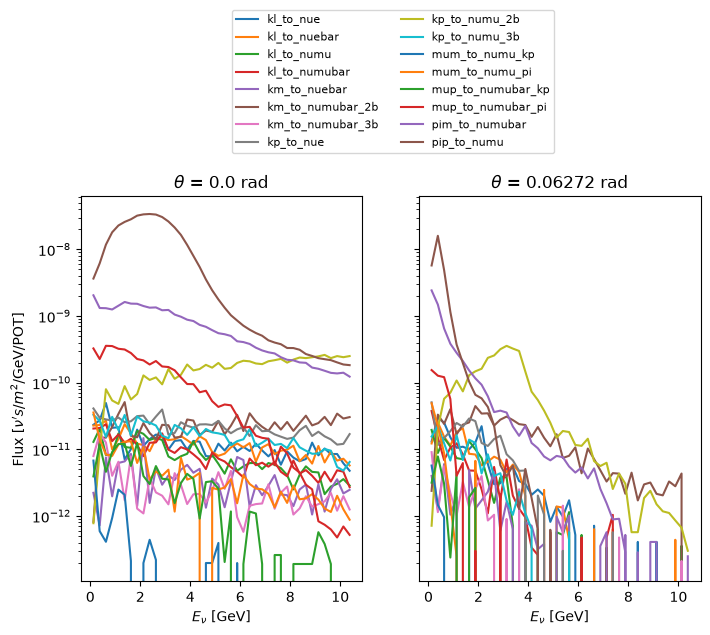

In [40]:
# ------- plot distribution of each decay process ---------- #

# set flux path and get files
flux_dir = Path("flux_histos/histtot/10_GeV")
files = sorted(flux_dir.glob("*offaxis*.txt"))

# load in fluxes at 0.0 and 0.06272 radians off axis and attach to histograms
hists0 = {}
hists06 = {}
for f in files:
    arr = np.loadtxt(f)
    if "06272" in f.stem:
        hists06[f.stem] = arr
    else:
        hists0[f.stem] = arr

# plot each decay process - use file name to set legend label
fig, ax = plt.subplots(1, 2, figsize=(8, 5), sharey=True)
for name, arr in hists0.items():
    ax[0].plot(arr[:, 0], arr[:, 1], label=name.replace("_offaxis0.0", ""))
for name, arr in hists06.items():
    ax[1].plot(arr[:, 0], arr[:, 1], label=name.replace("_offaxis0.06272", ""))

# set plot params
ax[0].set_xlabel(r"$E_\nu$ [GeV]")
ax[0].set_ylabel(r"Flux [$\nu's/m^2$/GeV/POT]")
ax[0].set_title(r"$\theta$ = 0.0 rad")
ax[0].legend(fontsize=8, ncol=2, bbox_to_anchor=(1.7, 1.5))
ax[0].set_yscale("log")

ax[1].set_xlabel(r"$E_\nu$ [GeV]")
ax[1].set_title(r"$\theta$ = 0.06272 rad")
ax[1].set_yscale("log")
plt.show()

### We will try to reconstruct the ratio of these flux contributions within the neutrino spectra below by fitting to the on-axis and off axis neutrino distributions

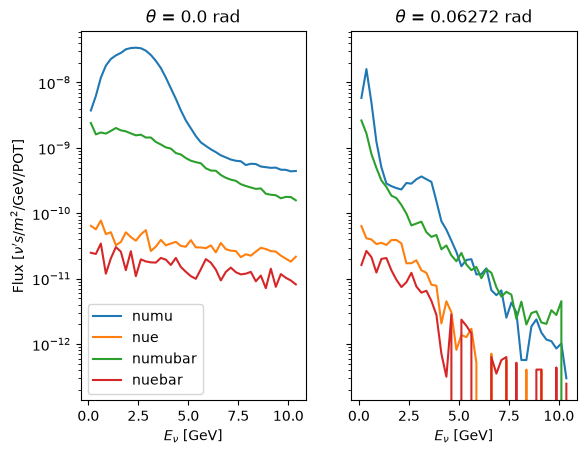

In [41]:
# ---------------------- plot distribution of each neutrino type by grouping decay processes together --------------------- #

# list flavours we want to group fluxes into
flavours = ["numu", "nue", "numubar", "nuebar"]
flux = {0.0: {}, 0.06272: {}}
theta = [0.0, 0.06272]
Enu = hists0["kl_to_nue_offaxis0.0"][:, 0]

# get files for parent particles decaying into each neutrino flavour
for th in theta:
    for fl in flavours:
        matches = (
            sorted(flux_dir.glob(f"*_to_{fl}_*offaxis{th}.txt"))
            + sorted(flux_dir.glob(f"*_to_{fl}_*offaxis{th}_pi.txt"))
            + sorted(flux_dir.glob(f"*_to_{fl}_*offaxis{th}_kp.txt"))
        )
        flav_stacks = [np.loadtxt(f)[:, 1] for f in matches]
        flux[th][fl] = np.sum(flav_stacks, axis=0) if flav_stacks else None

fig, ax = plt.subplots(1, 2, sharey=True)
for fl, y in flux[0.0].items():
    ax[0].plot(Enu, y, label=fl)
for fl, y in flux[0.06272].items():
    ax[1].plot(Enu, y, label=fl)
ax[0].set_yscale("log")
ax[0].legend()
ax[0].set_xlabel(r"$E_\nu$ [GeV]")
ax[0].set_ylabel(r"Flux [$\nu's/m^2$/GeV/POT]")
ax[0].set_title("$\\theta$ = 0.0 rad")

ax[1].set_yscale("log")
ax[1].set_xlabel(r"$E_\nu$ [GeV]")
ax[1].set_title("$\\theta$ = 0.06272 rad")
plt.show()


##### 3. Add detector efficiencies and neutrino interaction rates to neutrino histograms (while separating into flavour channels)

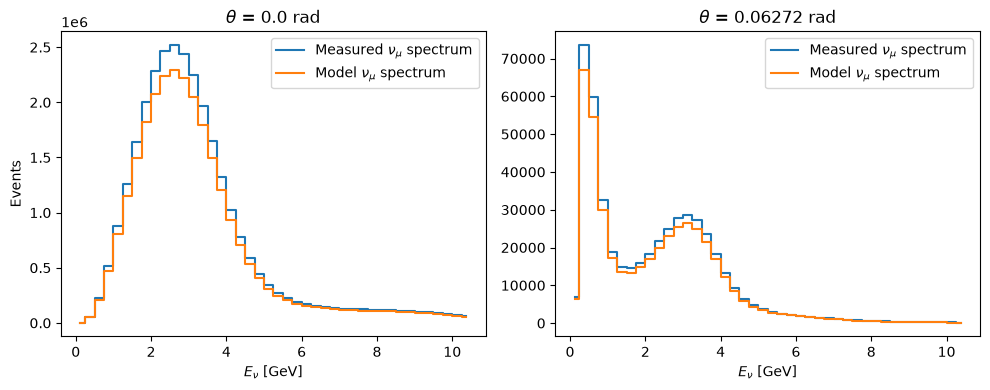

In [42]:
# ---------------------- plot fake measured neutrino dataset and modelled neutrino spectrum --------------------------- #

smear = False
param_xsec = True
POT = 1.1e21 * 6
flux_dir = "flux_histos/histtot/10_GeV/"
theta = [0.0, 0.06272]
pot_shares = [0.5, 0.5]
Ebins = np.arange(0.125, 10.625, 0.25)

# set ratios of neutrino parent particle in beam
# keep fit values at nominal but change in measured spectrum
fit_params = np.ones(5)  # p_kl, p_kp, p_km, p_pip, p_pim
meas_params = np.round(np.random.uniform(low=0.8, high=1.2, size=(5,)), 2)

initialize_xsecs(param_xsec)
initialize_fluxes(smear)
initialize_scaling(POT)
initialize_flux_dir(flux_dir)

# make "measured" spectra
meas_mu = [
    makeeventsmeas_fitparams_eff(th, meas_params, pot, Ebins, "muon", False)
    for th, pot in zip(theta, pot_shares)
]
Enu = meas_mu[0][:, 0]

# make model spectra from fluxFunction — setting nuisance parameters to nominal values
xsec_pars = (1, 1, 1, 1, 0, 0, 0, 0)  # Rqel, Rres, Rdis, Rmec, gammas
muon_funcs = [muon_0, muon_1]
pred_mu = [
    f(pot, Enu, *fit_params, *xsec_pars) for f, pot in zip(muon_funcs, pot_shares)
]

# plot neutrino spectra

fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
for i, th in enumerate(theta):
    ax[i].plot(
        Enu,
        meas_mu[i][:, 1],
        label=r"Measured $\nu_\mu$ spectrum",
        drawstyle="steps-mid",
    )
    ax[i].plot(
        Enu, pred_mu[i], label=r"Model $\nu_\mu$ spectrum", drawstyle="steps-mid"
    )
    ax[i].set_xlabel(r"$E_\nu$ [GeV]")
    ax[i].set_title(rf"$\theta$ = {th} rad")
    ax[i].legend()
ax[0].set_ylabel("Events")
plt.tight_layout()
plt.show()


##### 4. We can now use all flavours of the "measured" neutrino spectra and their models to do a fit with the migrad algorithm

##### Simplex is the minuit implementation of the Nelder-Mead method
 - Works by drawing a simplex (shape with N+1 points, where N is the number of dimensions of the function you want to minimise)
 - Then calculates value of function at each of the simplex points and ranks each point -> smallest best largest worst.
 - Then chooses an action to take on the worst point. These actions can be reflection, expansion, contraction, or shrinking.
 - Continues until some defined tolerance limit, traditionally on the standard deviation of the points.


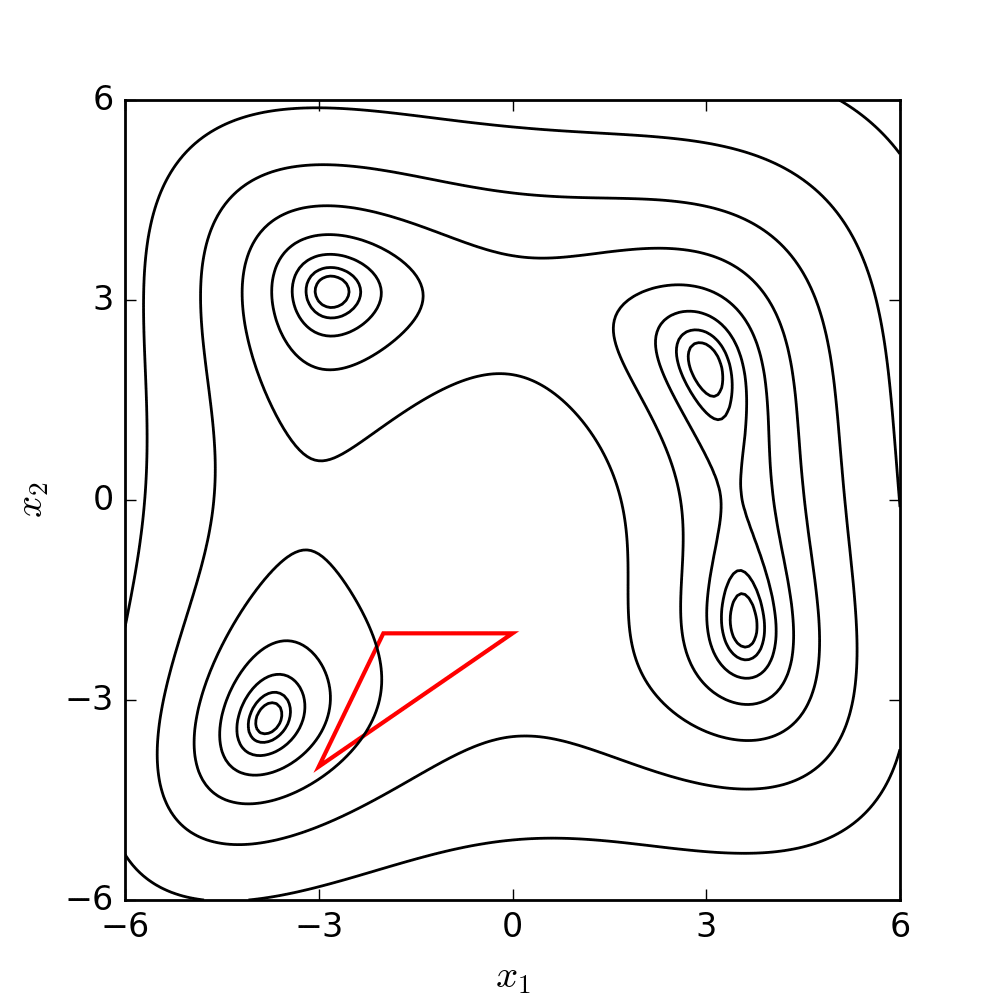

In [30]:
nelder_mead_path = Path("images/Nelder-Mead_Himmelblau.gif")
with open(nelder_mead_path, "rb") as f:
    display.display(display.Image(data=f.read(), format="gif", width=600))


Image By Nicoguaro - Own work, CC BY 4.0, https://commons.wikimedia.org/w/index.php?curid=51597577

##### Nelder-Mead is robust for functions which can have very large differences in values and is useful at the beginning of the optimisation, but can become very slow near the minimum. We therefore use `simplex` with a lax stopping criterion first, then apply a gradient descent minimiser `migrad` to get to the bottom of the minimum. It computes the covariance matrix while running, so also provides uncertainties on each parameter.

To perform fit, `run python off_axis_nuisance_all.py "demo_fit" 0`   

In [43]:
with open(
    "fit_outputs/fits/fitno_smear_param_xsec_bias_all_on_qgsp_demo_fit.pkl",
    "rb",
) as f:
    minuit_obj = pickle.load(f)


In [44]:
minuit_obj.fmin

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 2.623e-06                  │              Nfcn = 796              │
│ EDM = 2.62e-06 (Goal: 0.0002)    │           time = 99.9 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘

In [45]:
minuit_obj.params

,Name,Value,Hesse Error,Minos Error-,Minos Error+,Limit-,Limit+,Fixed
0,p_kl,1.00,0.17,,,0,,
1,p_kp,0.990,0.034,,,0,,
2,p_km,0.98,0.05,,,0,,
3,p_pip,1.000,0.033,,,0,,
4,p_pim,1.00,0.08,,,0,,
5,Rqel,1.00,0.04,,,,,
6,Rres,1.00,0.05,,,,,
7,Rdis,1.00,0.05,,,,,
8,Rmec,1.00,0.06,,,,,
9,gammaqel,-0.000,0.022,,,,,


In [46]:
minuit_obj.covariance

,p_kl,p_kp,p_km,p_pip,p_pim,Rqel,Rres,Rdis,Rmec,gammaqel,gammares,gammadis,gammamec
p_kl,0.0292,0.0000 (0.006),-0.0024 (-0.310),0.0015 (0.269),-0.009 (-0.677),-0.0008 (-0.105),0.0002 (0.025),-0.0032 (-0.339),-0.0003 (-0.027),0.4e-3 (0.110),-0.4e-3 (-0.070),0.29e-3 (0.117),0.001 (0.063)
p_kp,0.0000 (0.006),0.00114,0.0011 (0.695),0.0011 (0.950),0.0013 (0.472),-0.0008 (-0.512),-0.0011 (-0.712),-0.0014 (-0.777),-0.0003 (-0.132),0.2e-3 (0.258),-0.1e-3 (-0.058),-0.04e-3 (-0.085),0.0003 (0.146)
p_km,-0.0024 (-0.310),0.0011 (0.695),0.00209,0.0010 (0.641),0.0025 (0.661),-0.0009 (-0.420),-0.0010 (-0.495),-0.0012 (-0.502),-0.0003 (-0.106),0.1e-3 (0.122),-0.2e-3 (-0.111),-0.15e-3 (-0.227),0.0002 (0.069)
p_pip,0.0015 (0.269),0.0011 (0.950),0.0010 (0.641),0.00111,0.0008 (0.305),-0.0008 (-0.530),-0.0011 (-0.695),-0.0015 (-0.837),-0.0003 (-0.137),0.2e-3 (0.281),-0.1e-3 (-0.057),-0.03e-3 (-0.054),0.0003 (0.159)
p_pim,-0.009 (-0.677),0.0013 (0.472),0.0025 (0.661),0.0008 (0.305),0.00672,-0.0008 (-0.229),-0.0017 (-0.454),-0.0006 (-0.138),-0.0003 (-0.056),0.1e-3 (0.032),0.3e-3 (0.126),-0.30e-3 (-0.255),0.000 (0.017)
Rqel,-0.0008 (-0.105),-0.0008 (-0.512),-0.0009 (-0.420),-0.0008 (-0.530),-0.0008 (-0.229),0.00202,0.0005 (0.248),0.0006 (0.250),-0.0002 (-0.071),0.3e-3 (0.348),0.4e-3 (0.278),0.08e-3 (0.115),0.0006 (0.198)
Rres,0.0002 (0.025),-0.0011 (-0.712),-0.0010 (-0.495),-0.0011 (-0.695),-0.0017 (-0.454),0.0005 (0.248),0.0021,0.0007 (0.293),0.0002 (0.069),-0.3e-3 (-0.266),-0.8e-3 (-0.550),-0.32e-3 (-0.478),-0.0004 (-0.152)
Rdis,-0.0032 (-0.339),-0.0014 (-0.777),-0.0012 (-0.502),-0.0015 (-0.837),-0.0006 (-0.138),0.0006 (0.250),0.0007 (0.293),0.00296,0.0002 (0.060),-0.5e-3 (-0.409),0.6e-3 (0.351),0.31e-3 (0.385),-0.0008 (-0.230)
Rmec,-0.0003 (-0.027),-0.0003 (-0.132),-0.0003 (-0.106),-0.0003 (-0.137),-0.0003 (-0.056),-0.0002 (-0.071),0.0002 (0.069),0.0002 (0.060),0.00325,0.1e-3 (0.099),0.1e-3 (0.067),0.02e-3 (0.022),0.0002 (0.057)
gammaqel,0.4e-3 (0.110),0.2e-3 (0.258),0.1e-3 (0.122),0.2e-3 (0.281),0.1e-3 (0.032),0.3e-3 (0.348),-0.3e-3 (-0.266),-0.5e-3 (-0.409),0.1e-3 (0.099),0.000497,0.1e-3 (0.103),0.01e-3 (0.035),-0.5e-3 (-0.354)


### We've shown that we can reduce the uncertainties on neutrino production by combining data from different detector positions!